# Chapitre 6 - Cours 1 : Architecture RAG et algorithmes de recherche

Un modèle a besoin de deux choses pour résoudre une tâche : des **instructions** (communes à
toutes les requêtes, sujet du chapitre 5) et des **informations** propres à chaque requête.
Ce chapitre traite de la **construction du contexte**, avec deux grands schémas : le **RAG**
(*retrieval-augmented generation*, on va chercher l'information dans une mémoire externe) et
les **agents** (le modèle utilise des outils pour agir et s'informer).

Ce premier notebook couvre les sections *RAG*, *RAG Architecture* et *Retrieval Algorithms*
(jusqu'à *Comparing retrieval algorithms*) :

1. pourquoi construire un contexte : RAG contre « long contexte », en tokens et en dollars ;
2. l'architecture d'un système RAG (indexation, recherche, génération) et notre corpus jouet ;
3. la recherche par termes : fréquence des termes, IDF, index inversé, TF-IDF ;
4. BM25, implémenté à la main et comparé à `rank_bm25` ;
5. la recherche par embeddings (MiniLM anglais et multilingue) ;
6. la recherche vectorielle exacte et approchée (idées d'IVF et de HNSW, mesures avec FAISS) ;
7. la comparaison des deux familles (qualité, vitesse, coût).

In [1]:
import os

os.environ["HF_HUB_OFFLINE"] = "1"          # modèles déjà en cache : aucun appel réseau
os.environ["HF_HUB_VERBOSITY"] = "error"
import logging
import time
import warnings

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from transformers import AutoTokenizer

from aie import llm
from aie import ch06_rag_agents as c6
from aie.diagrams import Diagram
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 90)
P = c6.passages()
TEXTS, IDS = [p.text for p in P], [p.pid for p in P]
qwen_tok = AutoTokenizer.from_pretrained(llm.SMALL)  # tokenizer seul : pas de GPU nécessaire ici

## 1. Pourquoi construire un contexte ? (section *RAG*)

Le RAG consiste à **récupérer** (*retrieve*) les informations pertinentes dans une mémoire
externe (base de documents interne, historique de conversations, Web) puis à les donner au
modèle pour qu'il **génère** sa réponse. L'idée remonte au schéma « chercher puis lire » de
Chen et al. (2017) ; le terme RAG vient de Lewis et al. (2020).

**Intuition.** Un modèle sans contexte est comme un étudiant à un examen à livre fermé : il
répond de mémoire, et invente quand il ne sait pas. Le RAG lui donne, pour chaque question,
les quelques pages utiles du manuel. Le livre compare la construction du contexte à
l'**ingénierie des variables** (*feature engineering*) du ML classique : dans les deux cas, on
fournit au modèle l'information nécessaire pour traiter l'entrée.

Un long contexte rend-il le RAG inutile ? L'auteure pense que non, pour deux raisons :
(i) les données disponibles croissent plus vite que les fenêtres de contexte ; (ii) un modèle
qui *accepte* un long contexte ne l'*utilise* pas forcément bien, et chaque token coûte.
Chiffrons la seconde raison. Pour une base de $B$ tokens, une requête « tout dans le
contexte » consomme $B$ tokens d'entrée, alors qu'un RAG qui renvoie $k$ morceaux de $c$
tokens consomme environ $k\,c + q$ tokens (question comprise), **indépendamment de $B$**.
Côté calcul, le coût de l'attention du pré-remplissage croît même en $O(B^2)$.

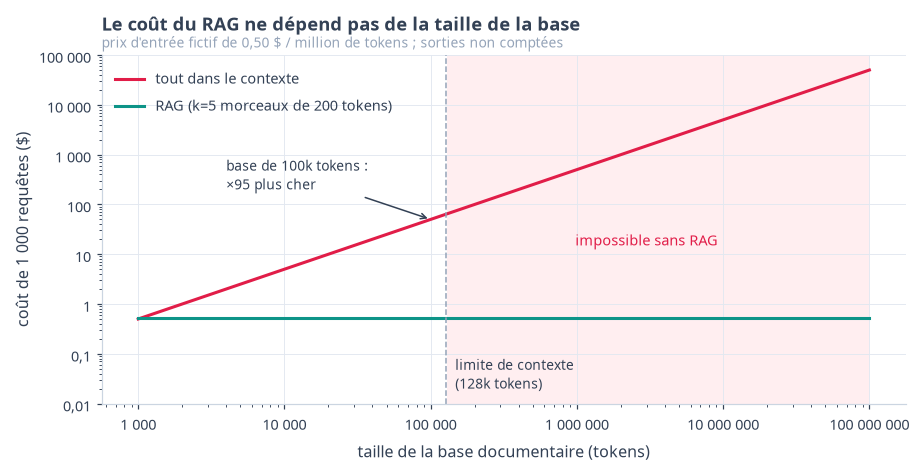

In [2]:
B = np.logspace(3, 8, 200)                       # taille de la base documentaire (tokens)
prix = 0.50 / 1e6                                 # prix fictif : 0,50 $ par million de tokens d'entrée
k, c, q = 5, 200, 50
cout_long = B * prix * 1000                       # coût pour 1 000 requêtes
cout_rag = np.full_like(B, (k * c + q) * prix * 1000)
limite = 128_000

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.loglog(B, cout_long, color=ROSE, label="tout dans le contexte")
ax.loglog(B, cout_rag, color=TEAL, label=f"RAG (k={k} morceaux de {c} tokens)")
ax.axvline(limite, color=GRAY, ls="--", lw=1)
ax.text(limite * 1.15, 2e-2, "limite de contexte\n(128k tokens)", fontsize=9, color=SLATE)
ax.fill_between(B[B > limite], 1e-3, 1e6, color=LIGHT[ROSE], alpha=0.6, lw=0)
ax.text(3e6, 1.5e1, "impossible sans RAG", color=ROSE, fontsize=9.5, ha="center")
ax.set_xlabel("taille de la base documentaire (tokens)")
ax.set_ylabel("coût de 1 000 requêtes ($)")
ax.set_ylim(1e-2, 1e5)
fmt = plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ") if v >= 1 else f"{v:g}".replace(".", ","))
ax.yaxis.set_major_formatter(fmt); ax.xaxis.set_major_formatter(fmt)
ax.set_title("Le coût du RAG ne dépend pas de la taille de la base", pad=16)
subtitle(ax, "prix d'entrée fictif de 0,50 $ / million de tokens ; sorties non comptées")
ax.legend(loc="upper left")
ratio = 100_000 / (k * c + q)
ax.annotate(f"base de 100k tokens :\n×{ratio:.0f} plus cher", xy=(1e5, 1e5 * prix * 1000), xytext=(4e3, 2e2),
            arrowprops=dict(arrowstyle="->", color=SLATE), fontsize=9)
finish(fig)
plt.show()

Même quand la base tient dans la fenêtre (Anthropic suggérait en 2024 de tout mettre dans le
prompt sous ~200 000 tokens pour Claude), chaque requête paie toute la base : pour 100 000
tokens, un facteur d'environ 100 par rapport à un RAG à 5 morceaux. Le *prompt caching*
(chapitre 9) atténue ce coût, mais pas la dilution de l'attention.

> **À retenir.** Le RAG construit un contexte **spécifique à chaque requête**. Son coût par
> requête est constant ($\approx k\,c$ tokens) alors que celui du « tout dans le contexte »
> croît avec la base ; au-delà de la fenêtre du modèle, il n'y a pas d'alternative.

## 2. Architecture d'un système RAG (section *RAG Architecture*)

Un système RAG a deux composants : un **retriever** (récupérateur) qui va chercher
l'information, et un **générateur** qui rédige la réponse. Le retriever a lui-même deux
fonctions : l'**indexation** (préparer les données hors ligne pour qu'on les retrouve vite) et
l'**interrogation** (*querying*). Les documents longs sont d'abord **découpés** en morceaux
(*chunks*) ; comme le livre, on appellera « document » aussi bien un document qu'un morceau.
Dans l'article original, retriever et générateur étaient entraînés ensemble ; aujourd'hui,
on assemble le plus souvent des composants pré-entraînés séparément.

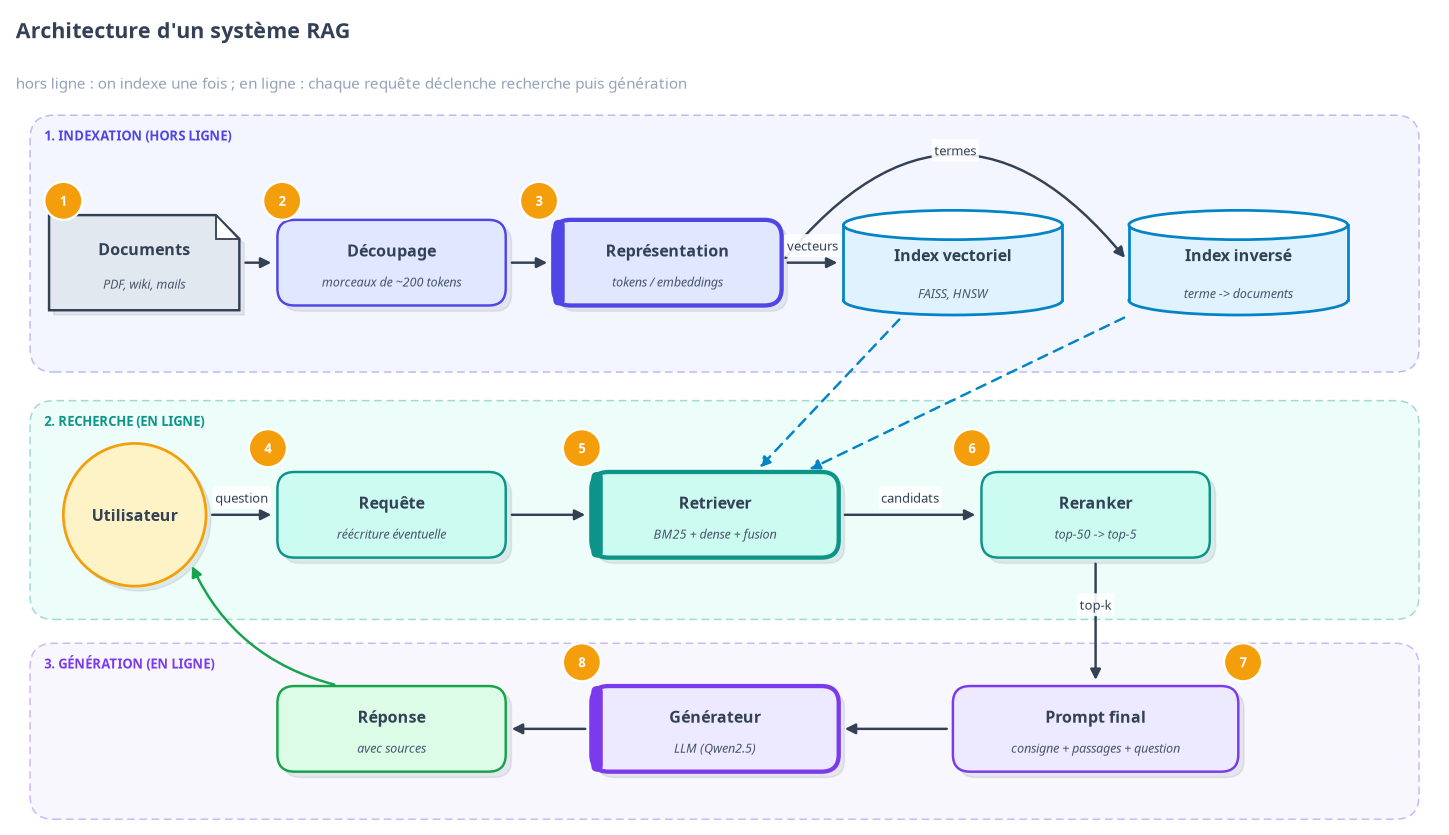

In [3]:
d = Diagram(15, 7.6, title="Architecture d'un système RAG",
            subtitle="hors ligne : on indexe une fois ; en ligne : chaque requête déclenche recherche puis génération")
d.group(0.2, 4.75, 14.8, 7.45, "1. Indexation (hors ligne)", color=INDIGO)
d.group(0.2, 2.15, 14.8, 4.45, "2. Recherche (en ligne)", color=TEAL)
d.group(0.2, 0.05, 14.8, 1.9, "3. Génération (en ligne)", color=VIOLET)
d.box("docs", 1.4, 5.9, "Documents", sub="PDF, wiki, mails", color=SLATE, kind="doc", w=2.0, h=1.0)
d.box("chunk", 4.0, 5.9, "Découpage", sub="morceaux de ~200 tokens", color=INDIGO, w=2.4)
d.box("enc", 6.9, 5.9, "Représentation", sub="tokens / embeddings", color=INDIGO, w=2.4, kind="model")
d.box("vec", 9.9, 5.9, "Index vectoriel", sub="FAISS, HNSW", color=SKY, kind="db", w=2.3, h=1.1)
d.box("inv", 12.9, 5.9, "Index inversé", sub="terme -> documents", color=SKY, kind="db", w=2.3, h=1.1)
d.arrow("docs", "chunk"); d.arrow("chunk", "enc"); d.arrow("enc", "vec", "vecteurs")
d.arrow("enc", "inv", "termes", rad=-0.62, label_offset=(0, 0.05))
d.box("user", 1.3, 3.25, "Utilisateur", color=AMBER, kind="user", w=1.5)
d.box("rew", 4.0, 3.25, "Requête", sub="réécriture éventuelle", color=TEAL, w=2.4)
d.box("ret", 7.4, 3.25, "Retriever", sub="BM25 + dense + fusion", color=TEAL, w=2.6, kind="model")
d.box("rr", 11.4, 3.25, "Reranker", sub="top-50 -> top-5", color=TEAL, w=2.4)
d.arrow("user", "rew", "question"); d.arrow("rew", "ret"); d.arrow("ret", "rr", "candidats")
d.arrow("vec", "ret", style="dashed", color=SKY); d.arrow("inv", "ret", style="dashed", color=SKY)
d.box("prompt", 11.4, 1.0, "Prompt final", sub="consigne + passages + question", color=VIOLET, w=3.0)
d.box("gen", 7.4, 1.0, "Générateur", sub="LLM (Qwen2.5)", color=VIOLET, kind="model", w=2.6)
d.box("ans", 4.0, 1.0, "Réponse", sub="avec sources", color=GREEN, w=2.4)
d.arrow("rr", "prompt", "top-k"); d.arrow("prompt", "gen"); d.arrow("gen", "ans")
d.arrow("ans", "user", color=GREEN, rad=-0.25)
for (x, y, t) in [(0.55, 6.55, "1"), (2.85, 6.55, "2"), (5.55, 6.55, "3"), (2.7, 3.95, "4"), (6.0, 3.95, "5"),
                  (10.1, 3.95, "6"), (12.95, 1.7, "7"), (6.0, 1.7, "8")]:
    d.badge(x, y, t)
d.show()

**Notre corpus.** Pour expérimenter, le module `aie.ch06_rag_agents` contient un petit corpus
français rédigé à la main : 10 documents (manuel d'un thermostat fictif « Thermo-X200 »,
guide RH d'une entreprise fictive « Calypso », boutique fictive de mode pour chats « Minou
Chic », erreurs réseau Linux, cuisine vietnamienne, système solaire, jardinage...), soit 64
passages, et **42 questions annotées** avec leurs passages pertinents. Deux documents parlent
de « transformateurs » (électriques et réseaux de neurones) et un troisième du film
*Transformers* : de quoi piéger la recherche lexicale. Les faits « fictifs » (prix, codes
d'erreur, règles RH) ne peuvent pas être connus du modèle : sans RAG, il ne peut qu'inventer.

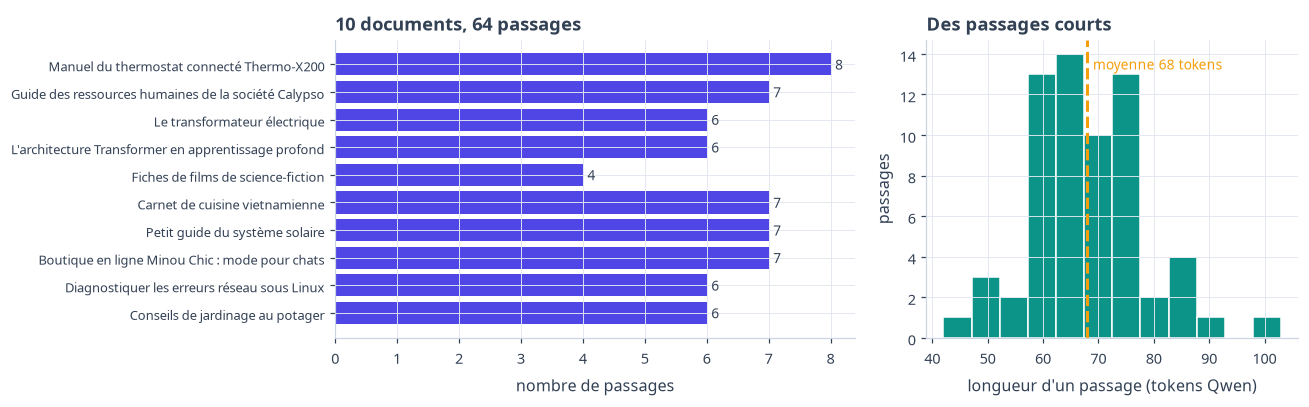

Types de questions : {'semantique': 20, 'lexical': 19, 'ambigu': 3}


,qid,question,relevant,type
0,q01,Que signifie le code E-42 sur le Thermo-X200 ?,{'thermo-4': 1},lexical
1,q08,Combien de jours de vacances ai-je par an chez Calypso ?,{'rh-1': 1},semantique
2,q15,Comment fonctionne un transformateur électrique ?,"{'transfo-1': 2, 'transfo-2': 1}",ambigu
3,q22,Quelles épices parfument le bouillon du phở ?,{'cuisine-1': 1},lexical
4,q29,Combien de temps la lumière solaire met-elle à nous parvenir ?,{'solaire-7': 1},semantique
5,q36,Que signifie l'erreur EADDRNOTAVAIL ?,{'reseau-2': 1},lexical


In [4]:
lens = np.array([len(qwen_tok(t)["input_ids"]) for t in TEXTS])
par_doc = pd.DataFrame({"document": [d_["title"] for d_ in c6.DOCUMENTS],
                        "passages": [len(d_["paragraphs"]) for d_ in c6.DOCUMENTS]})
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
ax.barh(par_doc.document[::-1], par_doc.passages[::-1], color=INDIGO)
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("nombre de passages"); ax.set_title("10 documents, 64 passages")
ax.tick_params(axis="y", labelsize=8.5)
ax = axes[1]
ax.hist(lens, bins=12, color=TEAL, edgecolor="white")
ax.axvline(lens.mean(), color=AMBER, ls="--")
ax.text(lens.mean() + 1, ax.get_ylim()[1] * 0.9, f"moyenne {lens.mean():.0f} tokens", color=AMBER, fontsize=9)
ax.set_xlabel("longueur d'un passage (tokens Qwen)"); ax.set_ylabel("passages")
ax.set_title("Des passages courts")
finish(fig); plt.show()
types = pd.Series([q["type"] for q in c6.QUESTIONS]).value_counts()
print("Types de questions :", types.to_dict())
pd.DataFrame([{k_: q[k_] for k_ in ["qid", "question", "relevant", "type"]} for q in c6.QUESTIONS[::7]])

Les questions sont de trois types : **lexicales** (elles reprennent les mots ou un code du
passage : « E-42 », « EADDRNOTAVAIL »), **sémantiques** (paraphrases sans mot commun : «
vacances » pour « congés payés ») et **ambiguës** (« transformer »).

> **À retenir.** Un RAG = un **retriever** (indexation hors ligne + interrogation en ligne)
> et un **générateur**. Sa qualité dépend d'abord de celle du retriever : un passage absent du
> contexte ne peut pas être utilisé.

## 3. Recherche par termes : TF, IDF et index inversé (section *Term-based retrieval*)

La recherche **lexicale** classe les documents selon les mots qu'ils partagent avec la requête.
Deux heuristiques :

- **fréquence du terme** $f(t, D)$ : plus un terme apparaît dans un document, plus celui-ci
  est probablement pertinent pour ce terme ;
- **fréquence documentaire inverse** : un terme présent partout (« pour », « de ») n'apporte
  rien. Avec $N$ documents dont $C(t)$ contiennent $t$ : $\mathrm{IDF}(t) = \log \frac{N}{C(t)}$.

Le score TF-IDF « naïf » du livre est alors
$$\mathrm{score}(D, Q) = \sum_{t \in Q} \mathrm{IDF}(t)\, f(t, D).$$

Avant tout, il faut **tokeniser** : minuscules, suppression des accents et de la ponctuation,
des mots vides, et ici une racinisation minimale (pluriels). Notre tokeniseur garde les codes
à tiret entiers, sinon « E-42 » deviendrait « e » et « 42 », beaucoup moins discriminants
(le livre cite le même problème avec « hot dog »).

In [5]:
for s in ["Que signifie le code E-42 sur le Thermo-X200 ?", "Quelles épices parfument le bouillon du phở ?"]:
    print(f"{s!r}\n  -> {c6.tokenize(s)}")
toks = [c6.tokenize(t) for t in TEXTS]
index = c6.build_inverted_index(toks)
exemple = ["tomate", "code", "transformateur", "e-42", "chat", "bouillon"]
pd.DataFrame([{"terme": t, "nb documents C(t)": len(index[t]), "IDF = log(N/C)": np.log(len(P) / len(index[t])),
               "(document, tf)": ", ".join(f"({IDS[i]}, {f})" for i, f in index[t][:4]) + (" ..." if len(index[t]) > 4 else "")}
              for t in exemple]).round(2)

'Que signifie le code E-42 sur le Thermo-X200 ?'
  -> ['signifie', 'code', 'e-42', 'thermo-x200']
'Quelles épices parfument le bouillon du phở ?'
  -> ['epice', 'parfument', 'bouillon', 'pho']


,terme,nb documents C(t),IDF = log(N/C),"(document, tf)"
0,tomate,3,3.06,"(jardin-1, 1), (jardin-4, 1), (jardin-5, 1)"
1,code,6,2.37,"(thermo-4, 2), (thermo-5, 1), (reseau-1, 1), (reseau-2, 1) ..."
2,transformateur,4,2.77,"(transfo-1, 1), (transfo-3, 1), (transfo-4, 1), (transfo-6, 1)"
3,e-42,1,4.16,"(thermo-4, 1)"
4,chat,2,3.47,"(minou-1, 1), (minou-4, 1)"
5,bouillon,3,3.06,"(cuisine-1, 2), (cuisine-6, 1), (cuisine-7, 1)"


L'index inversé (comme celui d'Elasticsearch, bâti sur Lucene) associe à chaque terme la liste
des documents qui le contiennent avec la fréquence : répondre à une requête ne demande de
parcourir que les listes de ses termes, pas tout le corpus. Visualisons l'IDF de tout le
vocabulaire : la loi de Zipf fait que la plupart des termes sont rares (IDF élevée).

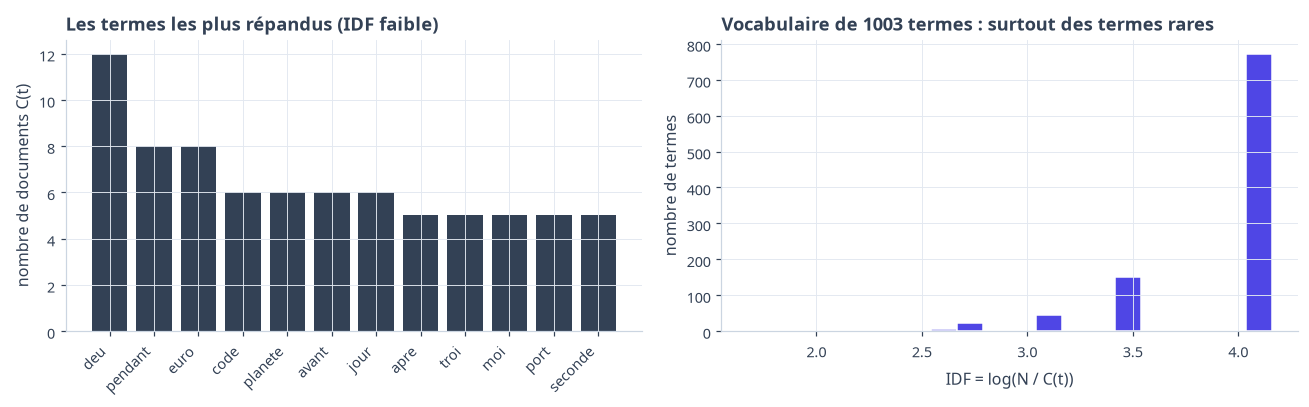

In [6]:
idf_all = np.array(sorted([np.log(len(P) / len(v)) for v in index.values()]))
dfreq = pd.Series({t: len(v) for t, v in index.items()}).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
top = dfreq.head(12)
ax.bar(top.index, top.values, color=SLATE)
ax.set_xticks(range(len(top))); ax.set_xticklabels(top.index, rotation=45, ha="right")
ax.set_ylabel("nombre de documents C(t)"); ax.set_title("Les termes les plus répandus (IDF faible)")
ax = axes[1]
ax.hist(idf_all, bins=20, color=INDIGO, edgecolor="white")
ax.set_xlabel("IDF = log(N / C(t))"); ax.set_ylabel("nombre de termes")
ax.set_title(f"Vocabulaire de {len(index)} termes : surtout des termes rares")
finish(fig); plt.show()

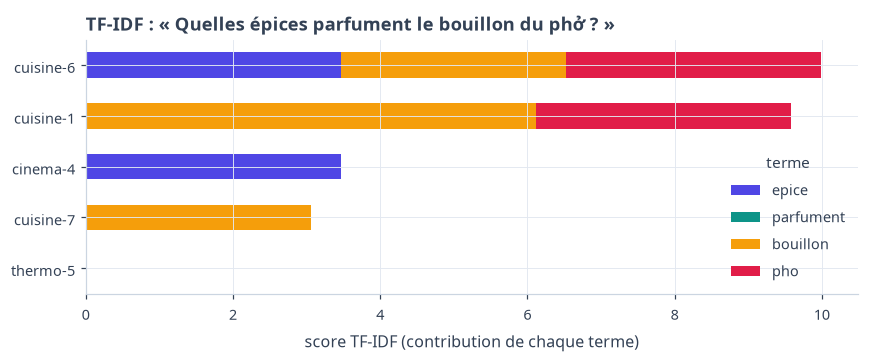

In [7]:
tfidf = c6.TfIdf(toks)
qtxt = "Quelles épices parfument le bouillon du phở ?"
s = tfidf.scores(c6.tokenize(qtxt))
top5 = np.argsort(-s)[:5]
contrib = pd.DataFrame({t: [tfidf.idf.get(t, 0) * toks[i].count(t) for i in top5] for t in c6.tokenize(qtxt)},
                       index=[IDS[i] for i in top5])
ax = contrib.plot.barh(stacked=True, figsize=(8, 3.4), color=[INDIGO, TEAL, AMBER, ROSE, VIOLET][:contrib.shape[1]])
ax.invert_yaxis(); ax.set_xlabel("score TF-IDF (contribution de chaque terme)")
ax.set_title("TF-IDF : « Quelles épices parfument le bouillon du phở ? »")
ax.legend(title="terme", loc="lower right"); plt.tight_layout(); plt.show()

Le passage attendu (`cuisine-1`, qui cite l'anis étoilé et la cannelle) n'utilise jamais le mot
« épice » : il ne marque des points qu'avec « bouillon » (deux fois) et « phở ». Le passage
`cuisine-6` (version végétarienne) contient le mot « épices » en plus de « bouillon » et «
phở » : il passe **devant**, alors qu'il ne répond pas à la question. La recherche lexicale ne
« comprend » pas, elle compte des mots.

> **À retenir.** TF-IDF = (combien de fois le terme apparaît) × (à quel point il est rare).
> L'**index inversé** rend la recherche très rapide ; la **tokenisation** (accents, codes,
> mots vides) conditionne fortement la qualité.